# 3. Visualization

Draw the `result/images/` style figures (ACF, correlation heatmap, cumulative-return histogram) per model and save them,
then verify that the yfinance source matches `data/indices.csv`.

- Models: ours (=`baseline`, C2C/w10), QuantGAN, TailGAN, Diffusion-TS.
- Saved to `result/images/{acf,correlation,histogram}/` (transparent-background PNG), same as before.
- yfinance: the five index/commodity series (DJI/NASDAQ/HSI/GOLD/WTI) were built from yfinance Close, so they must match.
  **JPM comes from CRSP (`data/JPM.csv`), a different source, so it may differ** (shown as-is).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.utils import *
from utils.metric import (
    correlation_mean, plot_correlation_heatmap, plot_acf_comparison,
    plot_cumulative_return_dist, plot_hist_row_by_model,
)
from utils.file_manager import LOCAL_BASE_DIRECTORY, quantDiffusionPath

file_manager = quantDiffusionPath()
SEQ_LEN = 256
SD = os.path.join(LOCAL_BASE_DIRECTORY, "result", "statistics", "synthetic_data")
feature_names = ["DJI", "NASDAQ", "JPM", "HSI", "GOLD", "WTI_OIL"]

# model: tag (folder) -> display name
MODELS = {
    "baseline": "QuantDiffusion (ours)",
    "quantgan": "QuantGAN",
    "tailgan": "TailGAN",
    "diffusionTS": "Diffusion-TS",
}

# real reference = test split of indices.csv, 6d (same as the benchmark)
df = pd.read_csv("./data/indices.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")
df.set_index("Date", inplace=True)
df = df.apply(pd.to_numeric).astype(float)
df_log_returns = np.log1p(df.pct_change()).dropna()
train_size = int(0.7 * len(df_log_returns))
test_raw = df_log_returns.iloc[train_size:, :]
real_data = np.transpose(rolling_window(test_raw.values, SEQ_LEN), (0, 2, 1))  # (B,6,T)
print("real_data (test 6d):", real_data.shape)

# load each model's synthetic data (set 0)
fakes = {}
for tag in MODELS:
    p = os.path.join(SD, tag, "0.npy")
    if os.path.exists(p):
        fakes[tag] = np.load(p)
    else:
        print(f"  (skip {tag}: {p} not found)")
print("loaded fakes:", {t: v.shape for t, v in fakes.items()})

real_data (test 6d): (1538, 6, 256)
loaded fakes: {'baseline': (2000, 6, 256), 'quantgan': (2000, 6, 256), 'tailgan': (2000, 6, 256), 'diffusionTS': (2000, 6, 256)}


c:\Users\Juhwankim\miniconda3\envs\research\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: invalid value encountered in log1p
  result = func(self.values, **kwargs)


## 3-1. Save figures (ACF, correlation, histogram)
Real reference + per-model synthetic saved under `result/images/`, and rendered inline.

In [2]:
IMG = file_manager.get_image_path()
ACF_DIR = os.path.join(IMG, "acf")
CORR_DIR = os.path.join(IMG, "correlation")
HIST_DIR = os.path.join(IMG, "histogram")
windows = [1, 5, 20, 100]

real_list = [real_data[:, i, :] for i in range(real_data.shape[1])]

# real correlation heatmap (once)
plot_correlation_heatmap(
    correlation_mean(np.transpose(real_data, (0, 2, 1))),
    "Real", feature_names, out_dir=CORR_DIR, name="real",
)

# per-model ACF + correlation + cumulative-return distribution
for tag, label in MODELS.items():
    if tag not in fakes:
        continue
    fake = fakes[tag]
    fake_list = [fake[:, i, :] for i in range(fake.shape[1])]
    plot_correlation_heatmap(
        correlation_mean(np.transpose(fake, (0, 2, 1))),
        label, feature_names, out_dir=CORR_DIR, name=tag,
    )
    plot_acf_comparison(real_list, fake_list, len(feature_names), lags=100,
                        out_dir=ACF_DIR, name=tag)
    plot_cumulative_return_dist(real_list, fake_list, windows=windows,
                                n_assets=len(feature_names), out_dir=HIST_DIR, name=tag)
    print(f"[plot] {tag}: saved acf/correlation/histogram")

# paper figure: JPM (asset 2), 5-day cumulative returns, one row across models
paper_order = [t for t in ["tailgan", "quantgan", "diffusionTS", "baseline"] if t in fakes]
plot_hist_row_by_model(
    real_data, {t: fakes[t] for t in paper_order}, MODELS, window=5, asset_idx=2,
    out_path=os.path.join(HIST_DIR, "paper_hist_5day_asset2_JPM.png"),
)
print("saved images ->", IMG)

[plot] baseline: saved acf/correlation/histogram
[plot] quantgan: saved acf/correlation/histogram
[plot] tailgan: saved acf/correlation/histogram
[plot] diffusionTS: saved acf/correlation/histogram
[hist] saved -> c:\Users\Juhwankim\Documents\Github\quantDiffusion\result/images\histogram\paper_hist_5day_asset2_JPM.png
saved images -> c:\Users\Juhwankim\Documents\Github\quantDiffusion\result/images


## 3-2. yfinance vs indices.csv match
The five index/commodity series were built from yfinance Close and should match exactly.
**JPM comes from CRSP (a different source), so it may differ.**

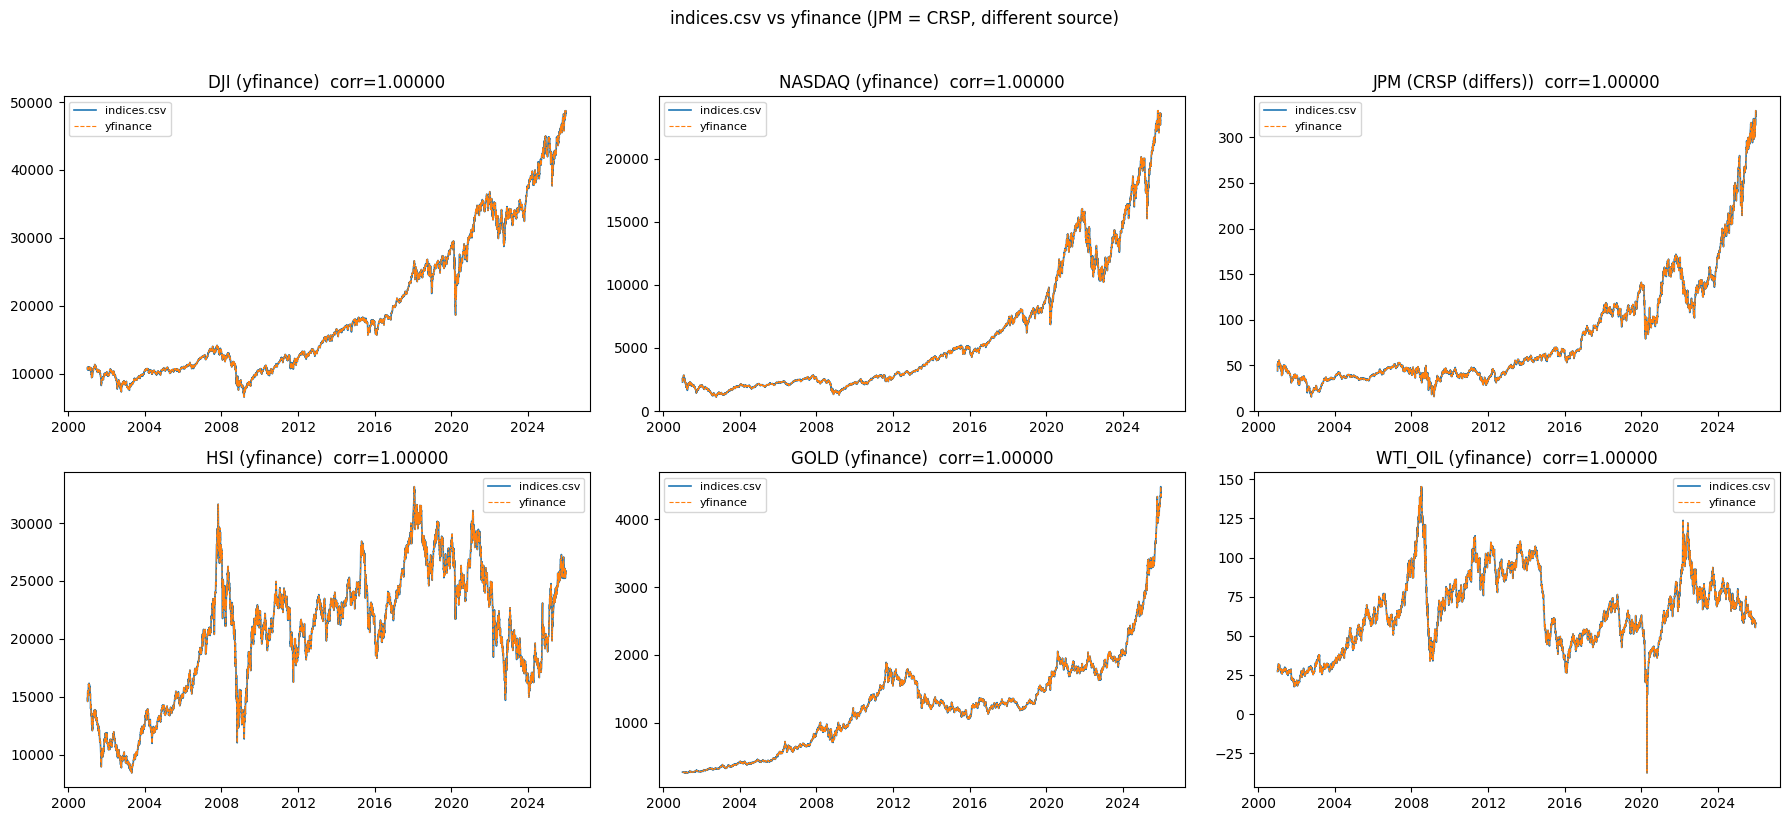

                 source  n_common  corr  max_rel_diff  median_rel_diff
asset                                                                 
DJI            yfinance      5979   1.0       0.00000              0.0
NASDAQ         yfinance      5979   1.0       0.00000              0.0
JPM      CRSP (differs)      5979   1.0       0.01103              0.0
HSI            yfinance      5979   1.0       0.00000              0.0
GOLD           yfinance      5979   1.0       0.00000              0.0
WTI_OIL        yfinance      5979   1.0       0.00000              0.0

Note: DJI/NASDAQ/HSI/GOLD/WTI_OIL are built from yfinance Close (exact match).
      JPM is sourced from CRSP (data/JPM.csv), a different source, so it may differ.


In [3]:
import yfinance as yf

# indices.csv column -> yfinance ticker
TICKER_MAP = {"DJI": "^DJI", "NASDAQ": "^IXIC", "JPM": "JPM",
              "HSI": "^HSI", "GOLD": "GC=F", "WTI_OIL": "CL=F"}
# JPM in indices.csv is from CRSP, not yfinance -> may differ
YF_SOURCE = {"DJI": "yfinance", "NASDAQ": "yfinance", "HSI": "yfinance",
             "GOLD": "yfinance", "WTI_OIL": "yfinance", "JPM": "CRSP (differs)"}

start = df.index.min().strftime("%Y-%m-%d")
end = (df.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
raw = yf.download(list(TICKER_MAP.values()), start=start, end=end,
                  auto_adjust=False, progress=False)
close = raw["Close"] if isinstance(raw.columns, pd.MultiIndex) else raw
inv = {v: k for k, v in TICKER_MAP.items()}
yf_close = close.rename(columns=inv)[list(TICKER_MAP.keys())]

# compare on common dates
rows = []
fig, axs = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axs.ravel(), feature_names):
    a = df[col].dropna()
    b = yf_close[col].dropna()
    common = a.index.intersection(b.index)
    a2, b2 = a.loc[common], b.loc[common]
    corr = a2.corr(b2)
    rel = np.abs(a2 - b2) / (np.abs(a2) + 1e-8)
    rows.append({"asset": col, "source": YF_SOURCE[col], "n_common": len(common),
                 "corr": round(corr, 6), "max_rel_diff": round(float(rel.max()), 5),
                 "median_rel_diff": round(float(rel.median()), 6)})
    ax.plot(a2.index, a2.values, label="indices.csv", lw=1.2)
    ax.plot(b2.index, b2.values, label="yfinance", lw=0.8, ls="--")
    ax.set_title(f"{col} ({YF_SOURCE[col]})  corr={corr:.5f}")
    ax.legend(fontsize=8)
fig.suptitle("indices.csv vs yfinance (JPM = CRSP, different source)", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(file_manager.get_image_path(), "yfinance_match.png"),
            dpi=150, bbox_inches="tight")
plt.show()

match = pd.DataFrame(rows).set_index("asset")
print(match.to_string())
print("\nNote: DJI/NASDAQ/HSI/GOLD/WTI_OIL are built from yfinance Close (exact match).")
print("      JPM is sourced from CRSP (data/JPM.csv), a different source, so it may differ.")